# Análise Exploratória de Dados (EDA) e Higienização 

Este notebook conduz a investigação estatística e comportamental da carteira de crédito do dataset *Give Me Some Credit*, pavimentando o caminho para a engenharia de recursos.

---
## Hipóteses Iniciais de Risco
Antes de auditar os dados brutos, estabelecemos as premissas centrais que serão testadas empiricamente nesta etapa:
* **Hipótese 1 (Utilização de Crédito):** Clientes que operam com taxas de utilização de linhas rotativas (`RevolvingUtilizationOfUnsecuredLines`) próximas ou superiores a 100% concentram a esmagadora maioria dos eventos de default (`SeriousDlqin2yrs`).

* **Hipótese 2 (Histórico de Atrasos):** A reincidência de atrasos curtos de 30 a 59 dias (`NumberOfTime30-59DaysPastDueNotWorse`) possui poder discriminatório superior à renda ou idade isoladas.

* **Hipótese 3 (Assimetria de Renda):** A ausência de dados em renda mensal (`MonthlyIncome`) possui padrão sistemático e requer imputação combinada com uma flag binária de controle.

## Objetivos da Etapa
1. Conexão com o banco SQLite (`credit_scoring.db`) e leitura eficiente da base.
2. Auditoria de valores ausentes (*missing values*) e tratamento de outliers físicos ou de coleta.
3. Validação gráfica e estatística das hipóteses iniciais para confirmar o comportamento do desbalanceamento da carteira.

---
Para garantir total clareza na interpretação das análises e dos modelos, abaixo está detalhado a estrutura do dataset *Give Me Some Credit* e a **Variável Alvo (Target)**:

### Variável Alvo (Target)
* **`SeriousDlqin2yrs` (Binária):** Indicador de inadimplência grave. Assume valor `1` se o cliente apresentou atraso superior a 90 dias em suas obrigações financeiras nos últimos 2 anos, e `0` caso contrário. É o foco principal da modelagem preditiva.

### Variáveis Preditivas (Features)
* **`RevolvingUtilizationOfUnsecuredLines`:** Percentual de saldo devedor em relação ao limite total disponível em linhas de crédito rotativo (cartões de crédito e cheque especial).
* **`age`:** Idade do cliente em anos.
* **`NumberOfTime30-59DaysPastDueNotWorse`:** Número de vezes que o cliente atrasou o pagamento entre 30 e 59 dias nos últimos 2 anos.
* **`DebtRatio`:** Comprometimento mensal de renda (razão entre pagamentos de dívidas, aluguel, etc., e a renda mensal bruta).
* **`MonthlyIncome`:** Renda mensal declarada do cliente.
* **`NumberOfOpenCreditLinesAndLoans`:** Quantidade de empréstimos e linhas de crédito ativas (cartões, financiamentos, etc.).
* **`NumberOfTimes90DaysLate`:** Número de vezes que o cliente ficou 90 dias ou mais atrasado em suas obrigações.
* **`NumberRealEstateLoansOrLines`:** Quantidade de financiamentos ou empréstimos imobiliários (hipotecas).
* **`NumberOfTime60-89DaysPastDueNotWorse`:** Número de vezes que o cliente atrasou o pagamento entre 60 e 89 dias nos últimos 2 anos.
* **`NumberOfDependents`:** Número de dependentes na residência do cliente.

In [1]:
## Imports e Conexão com o banco de dados

# Importação das bibliotecas essenciais para EDA e manipulação de dados
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração para exibir todas as colunas e gráficos no Jupyter
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

print("Bibliotecas importadas com sucesso!\n")

# Conexão com o banco SQLite criado na ingestão
caminho_db = "../data/credit_scoring.db"
conexao = sqlite3.connect(caminho_db)

# Carregando os dados de treino para um DataFrame do Pandas
df = pd.read_sql("SELECT * FROM credito_treino", conexao)
conexao.close()

print(f"Dados carregados do banco SQLite! \nDimensões do DataFrame: {df.shape[0]} linhas e {df.shape[1]} colunas.")

Bibliotecas importadas com sucesso!

Dados carregados do banco SQLite! 
Dimensões do DataFrame: 150000 linhas e 11 colunas.


## Auditoria Inicial: Tipos de Dados e Valores Ausentes (*Missing Values*)

Nessa etapa, vamos inspecionar o esquema do DataFrame para verificar os tipos de dados de cada coluna e mapear a presença de valores nulos. 

In [2]:
## Análise de Nulos e Tipos

# Verificando informações gerais do DataFrame e tipos de dados
print("Informações gerais do DataFrame:")
display(df.info())

print("\n" + "="*50 + "\n")

# Analisando os valores nulos absolutos e percentuais 
nulos = df.isnull().sum()
percentual_nulos = (df.isnull().mean() * 100).round(2)

df_nulos = pd.DataFrame({
    'Valores Nulos': nulos,
    'Porcentagem (%)': percentual_nulos
})

print("Auditoria de Valores Ausentes:")
display(df_nulos[df_nulos['Valores Nulos'] > 0])


Informações gerais do DataFrame:
<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 0 to 149999
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 n

None



Auditoria de Valores Ausentes:


,Valores Nulos,Porcentagem (%)
MonthlyIncome,29731,19.82
NumberOfDependents,3924,2.62


Com base na auditoria, podemos definir a estratégia para as únicas duas variáveis que apresentam nulos, garantindo a integridade da amostra para as próximas etapas:

* **`MonthlyIncome` (19.82% de nulos):** Como a renda é um preditor crítico em risco de crédito, a exclusão de linhas ou da coluna está descartada. Será realizada a **imputação estatística (mediana)** e criada uma **flag binária indicadora de ausência**, permitindo que o modelo capture se a omissão de renda possui correlação com o default.

* **`NumberOfDependents` (2.62% de nulos):** Devido ao baixo percentual de ausência, faremos a **imputação simples por mediana/moda**, evitando ruídos desnecessários.

* **Demais colunas (0% de nulos):** O restante da base está íntegro, sem registros corrompidos ou falhas estruturais de coleta.

## Estatística Descritiva e Identificação de Anomalias (*outliers*)

Nessa etapa, vamos analisar as estatísticas descritivas do DataFrame para identificar valores que fogem da realidade (como idades inválidas) e os códigos de artefato do dataset (como 96 e 98 nas colunas atraso).

In [3]:
# Estatísticas descritivas para inspeção (mínimo, máximo, média e quartis)
print("Estatísticas Descritivas Básicas:")
display(df.describe().T)

# Verificando valores únicos nas colunas de atraso para identificar códigos de erro/artefatos
print("\n Investigando valores únicos nas colunas de histórico de atraso:")
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols_atraso:
    print(f"\nValores únicos em {col}:")
    print(sorted(df[col].unique()))

Estatísticas Descritivas Básicas:


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0



 Investigando valores únicos nas colunas de histórico de atraso:

Valores únicos em NumberOfTime30-59DaysPastDueNotWorse:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(96), np.int64(98)]

Valores únicos em NumberOfTimes90DaysLate:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(17), np.int64(96), np.int64(98)]

Valores únicos em NumberOfTime60-89DaysPastDueNotWorse:
[np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(11), np.int64(96), np.int64(98)]


A inspeção estatística e a verificação de cardinalidade permitiu identificar os seguintes pontos de atenção e suas respectivas diretrizes de tratamento para as próximas etapas:

* Idade Mínima (`age`): Encontramos `min = 0`, o que biologicamente é impossível para tomadores de crédito. Precisamos filtrar ou tratar essas linhas.

* Os Valores `96` e `98` nas Colunas de Atraso: Nas colunas `NumberOfTime30-59DaysPartDueNotWorse`, `NumberOfTimes90DaysLate` e `NumberOfTime60-89DaysPastDueNotWorse`, os valores únicos revelam a presença de `96` e `98`. Na documentação desse dataset, esses números não representam dias de atraso reais, mas sim códigos de sistema / valores especiais (geralmente indicando ausência de dados, clientes inativos ou casos omissos). Menter esses valores como números faria o algoritmo achar que um cliente atrasou 98 vezes, distorcendo totalmente o modelo de risco. Precisamos tratá-los (convertendo para nulos ou imputando adequadamente).

* Utilização de Crédito e Dívida (`RevolvingUtilizationOfUnsecuredLines` e `DebtRatio`): Apresentam valores máximos absurdamente altos (ex: utilidade acima de 50.000 e dívidas desproporcionais), indicando prováveis distorções ou limites de crédito zerados que geram divisão por zero. Precisamos analisar o impacto e podar esses extremos (*winsorização* ou filtros lógicos).

## Tratamento de Anomalias e Erros de Coleta

Para garantir que o modelo de ML não aprenda padrões falsos, vamos aplicar as seguintes correções:
* **Idade (`age`):** Remover linhas onde a idade é igual a 0 (erro de cadastro).

* **Códigos de Sistema (`96` e `98`):** Substituir os códigos de artefato nas colunas de histórico de atraso por `NaN` (valores nulos), permitindo que sejam tratados de forma unificada na etapa de imputação. 

In [4]:
## Aplicando o Tratamento

# Fazendo uma cópia do DataFrame original para preserver o estado bruto 
df_limpo = df.copy()

print(f"Dimensões antes da limpeza: {df_limpo.shape}")

# Removendo linhas com idade igual a 0
linhas_idade_zerada = df_limpo[df_limpo['age'] == 0].shape[0]
df_limpo = df_limpo[df_limpo['age'] > 0]
print(f"Removidas {linhas_idade_zerada} linhas com idade igual a 0.")

# Substituindo os códigos 96 e 98 por NaN nas colunas de atraso
cols_atraso = [
    'NumberOfTime30-59DaysPastDueNotWorse',
    'NumberOfTimes90DaysLate',
    'NumberOfTime60-89DaysPastDueNotWorse'
]

for col in cols_atraso:
    qtd_anomalias = df_limpo[df_limpo[col].isin([96, 98])].shape[0]
    # Substitui 96 e 98 por NaN
    df_limpo[col] = df_limpo[col].replace([96, 98], np.nan)
    print(f"Substituídos {qtd_anomalias} valores (96/98) por NaN na coluna {col}.")

print(f"\nDimensões após a limpeza inicial de anomalias: {df_limpo.shape}")

Dimensões antes da limpeza: (150000, 11)
Removidas 1 linhas com idade igual a 0.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTime30-59DaysPastDueNotWorse.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTimes90DaysLate.
Substituídos 269 valores (96/98) por NaN na coluna NumberOfTime60-89DaysPastDueNotWorse.

Dimensões após a limpeza inicial de anomalias: (149999, 11)


Idade (`age`): Apenas 1 linha apresentava idade igual a 0, sendo removida sem impacto relevante no volume total da base.

Códigos de Sistema (`96`e `98`): Foram neutralizados 269 registros em cada uma das três colunas de histórico de atraso, convertendo em valores nulos (`NaN`).

---
Com os erros e artefatos eliminados, a base está limpa de "fantasmas". Podemos avançar para a análise de distribuição da variável alvo (`SeriousDlqin2yrs`) e a definição da estratégia de imputação para os valores restantes (`MonthlyIncome`, `NumberOfDependents` e os novos `NaN` gerados nas colunas de atraso).

## Análise da Variável Alvo (`SeriousDlqin2yrs`)

A variável alvo indica se o cliente enfretou dificuldades financeiras graves (atraso superior a 90 dias) nos últimos 2 anos (1 = Inadimplente/Mau Pagador, 0 = Bom pagador). Vamos verificar a proporção de cada classe para medir o desbalanceamento.

Distribuição da Variável Alvo (SeriousDlqin2yrs):


,Quantidade,Porcentagem (%)
SeriousDlqin2yrs,,
0,139973,93.32
1,10026,6.68


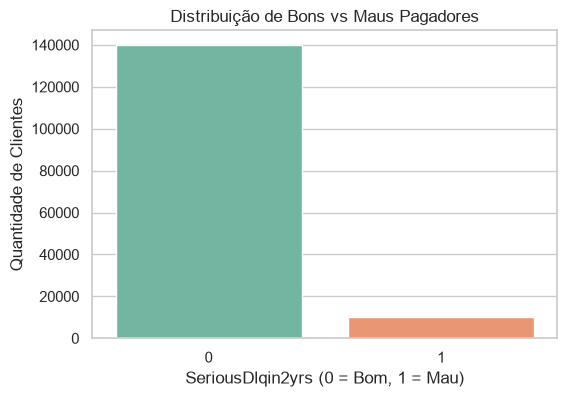

In [5]:
## Distribuição da Target

import os 

# Calculando a contagem e % da variável alvo
alvo_counts = df_limpo['SeriousDlqin2yrs'].value_counts()
alvo_perc = df_limpo['SeriousDlqin2yrs'].value_counts(normalize=True) * 100

df_alvo_analise = pd.DataFrame({
    'Quantidade': alvo_counts,
    'Porcentagem (%)': alvo_perc.round(2)
})

print("Distribuição da Variável Alvo (SeriousDlqin2yrs):")
display(df_alvo_analise)

# Gráfico de barras para visualizar o desbalanceamento
plt.figure(figsize=(6, 4))
sns.countplot(
    x='SeriousDlqin2yrs', 
    data=df_limpo, 
    hue='SeriousDlqin2yrs',
    palette='Set2',
    legend=False)
plt.title('Distribuição de Bons vs Maus Pagadores')
plt.xlabel('SeriousDlqin2yrs (0 = Bom, 1 = Mau)')
plt.ylabel('Quantidade de Clientes')

# Salvando a imagem 
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True) 
caminho_imagem = os.path.join(output_dir, "distribuicao_bons_vs_maus_pgds.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

Desbalanceamento Severo de Classes: O gráfico e a tabela mostram que a base é altamente desbalanceada. A grande maioria dos clientes  é composta por bons pagadores (`0`), enquanto os maus pagadores (`1`) representam uma fração minoritária (cerca de 6,7%).

Deafio para a Modelagem: Isso significa que a a acurácia não serve como métrica de sucesso (um modelo que chuta sempre "0" teria mais de 93% de acurácia, mas quebraria o banco). Ou seja, nas etapas de modelagem, teremos que utilizar métricas focadas na capacidade de separação e na classe minoritária, como a **ROC-AUC**, a **Curva Precision-Recall** e a **Estatística KS**.

## Validação da Hipótese 1: Impacto da Utilização de Crédito (`RevolvingUtilizationOfUnsecuredLines`)

- Clientes que operam com taxas de utilização de linhas rotativas próximas ou superiores a 100% (1.0) concentram a esmagadora maioria dos eventos de default (`SeriousDlqin2yrs`).

Para testar essa premissa, vamos segmentar a utilização em faixas estratégicas e calcular a taxa de inadimplência em cada uma delas.

Taxa de Inadimplência por Faixa de Utilização de Crédito:


,faixa_utilizacao,total_clientes,inadimplentes,taxa_inadimplencia (%)
0,Até 30%,92882,2061,2.22
1,30% a 60%,21887,1462,6.68
2,60% a 100%,31909,5266,16.50
3,100% a 200%,2950,1183,40.10
4,Acima de 200%,371,54,14.56


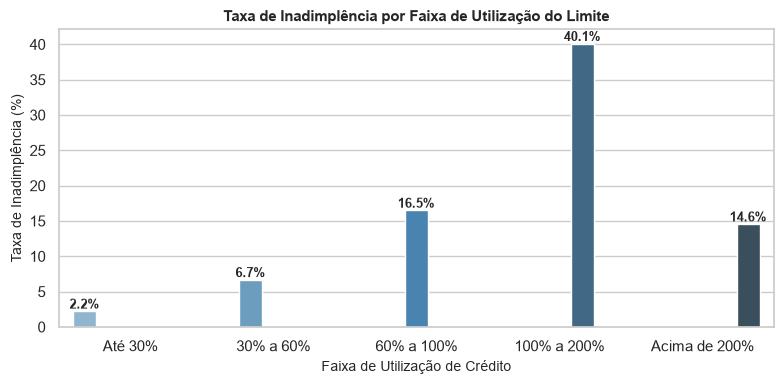

In [6]:
# Criando cópia temporária para análise da faixa de utilização
df_h1 = df_limpo.copy()

# Definindo faixas (bins) intuitivas para a taxa de utilização
# Faixas: até 30%, 30%-60%, 60%-100%, 100%-200%, e acima de 200% (para capturar os extremos)
bins = [-0.001, 0.3, 0.6, 1.0, 2.0, float('inf')]
labels = ['Até 30%', '30% a 60%', '60% a 100%', '100% a 200%', 'Acima de 200%']

df_h1['faixa_utilizacao'] = pd.cut(df_h1['RevolvingUtilizationOfUnsecuredLines'], bins=bins, labels=labels)

# Calculando a taxa de inadimplência (média da target) e a quantidade de clientes por faixa
analise_h1 = df_h1.groupby('faixa_utilizacao', observed=False)['SeriousDlqin2yrs'].agg(
    total_clientes='count',
    inadimplentes='sum',
    taxa_inadimplencia='mean'
).reset_index()

analise_h1['taxa_inadimplencia (%)'] = (analise_h1['taxa_inadimplencia'] * 100).round(2)

print("Taxa de Inadimplência por Faixa de Utilização de Crédito:")
display(analise_h1[['faixa_utilizacao', 'total_clientes', 'inadimplentes', 'taxa_inadimplencia (%)']])

# Visualização gráfica da Hipótese 1
plt.figure(figsize=(8, 4))
ax = sns.barplot(
    x='faixa_utilizacao', 
    y='taxa_inadimplencia (%)', 
    data=analise_h1, 
    palette='Blues_d',
    hue='faixa_utilizacao',
    legend=False
)
plt.title('Taxa de Inadimplência por Faixa de Utilização do Limite', fontsize=11, fontweight='bold')
plt.xlabel('Faixa de Utilização de Crédito', fontsize=10)
plt.ylabel('Taxa de Inadimplência (%)', fontsize=10)

for p in ax.patches:
    height = p.get_height() # type: ignore 
    ax.annotate(f'{height:.1f}%',
                (p.get_x() + p.get_width() / 2., height), # type: ignore
                ha='center', va='bottom',
                fontsize=9, fontweight='bold') 

# Salvando a imagem 
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True) 
caminho_imagem = os.path.join(output_dir, "taxa_inadimplencia_faixa_utlz.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')


plt.tight_layout()
plt.show()

**Hipótese 1: Confirmada (com ressalva de outliers)**

- Monotonicidade do Risco: A hipótese se confirma com clareza nas faixas operacionais normais. Existe uma relação diretamente proporcional entre a utilização do limite rotativo e o default: a inadimplência parte de 2,22% (uso até 30%) e atinge o pico de 40,10% no intervalo de 100% a 200% de utilização.

- Evidência de Outliers (Acima de 200%): A queda aparente na taxa para 14,56% em utilizações extremas (>200%) decorre do reduzido volume de observações (apenas 371 casos) combinado a anomalias de cadastro (ex: limites zerados que inflam a razão). 

Essa variável possui alto valor discriminatório. Na etapa de engenharia de recursos, faz sentido criar faixas (*bins*) de risco e aplicar tratamento de valores extremos (*clipping/winsorization*) para blindar o modelo contra essas distorções.

## Validação da Hipótese 2: Impacto do Histórico de Atrasos Curtos (`NumberOfTime30-59DaysPastDueNotWorse`)

- A ocorrência de atrasos curtos (30 a 59 dias) possui poder preditivo direto na inadimplência final. Clientes com reincidência de atrasos leves apresentam probabilidade substancialmente maior de default em relação aos pontuais.

Taxa de Inadimplência por Ocorrência de Atrasos (30-59 Dias):


,atrasos_30_59_cat,total_clientes,inadimplentes,taxa_inadimplencia (%)
0,0,126018,5041,4.00
1,1,16032,2409,15.03
2,2,4598,1219,26.51
3,3+,3082,1210,39.26
4,Ausente/Erro,269,147,54.65


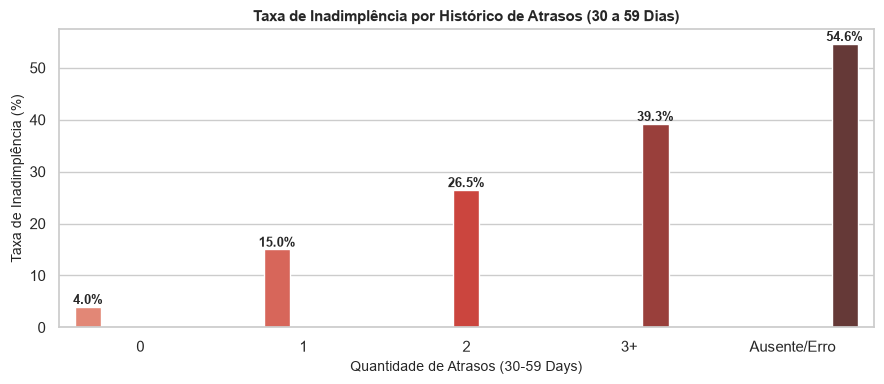

In [7]:
# Criando cópia temporária
df_h2 = df_limpo.copy()

# Definindo condições lógicas limpas para o agrupamento
s = df_h2['NumberOfTime30-59DaysPastDueNotWorse']

condicoes = [
    s.isna(),  # Captura todos os nulos (incluindo os 96/98 que viraram NaN)
    s == 0,
    s == 1,
    s == 2,
]

escolhas = ['Ausente/Erro', '0', '1', '2']

# np.select avalia as condições em ordem; o que sobra cai no default ('3+')
df_h2['atrasos_30_59_cat'] = np.select(condicoes, escolhas, default='3+')

# Calculando a taxa de inadimplência por categoria de atrasos
analise_h2 = (
    df_h2.groupby('atrasos_30_59_cat', observed=False)['SeriousDlqin2yrs']
    .agg(
        total_clientes='count',
        inadimplentes='sum',
        taxa_inadimplencia='mean',
    )
    .reset_index()
)

analise_h2['taxa_inadimplencia (%)'] = (
    analise_h2['taxa_inadimplencia'] * 100
).round(2)

# Ordenando explicitamente as categorias para o gráfico e tabela
ordem_cat = ['0', '1', '2', '3+', 'Ausente/Erro']
analise_h2['atrasos_30_59_cat'] = pd.Categorical(
    analise_h2['atrasos_30_59_cat'], categories=ordem_cat, ordered=True
)
analise_h2 = analise_h2.sort_values('atrasos_30_59_cat')

print('Taxa de Inadimplência por Ocorrência de Atrasos (30-59 Dias):')
display(analise_h2[['atrasos_30_59_cat', 'total_clientes', 'inadimplentes', 'taxa_inadimplencia (%)']])

# Visualização gráfica 
plt.figure(figsize=(9, 4))
ax = sns.barplot(
    x='atrasos_30_59_cat',
    y='taxa_inadimplencia (%)',
    data=analise_h2,
    palette='Reds_d',
    hue='atrasos_30_59_cat',
    legend=False,
)
plt.title(
    'Taxa de Inadimplência por Histórico de Atrasos (30 a 59 Dias)',
    fontsize=11,
    fontweight='bold',
)
plt.xlabel('Quantidade de Atrasos (30-59 Days)', fontsize=10)
plt.ylabel('Taxa de Inadimplência (%)', fontsize=10)

for p in ax.patches:
  height = p.get_height() # type: ignore
  if pd.notnull(height) and height > 0:
    ax.annotate(
        f'{height:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height), # type: ignore
        ha='center',
        va='bottom',
        fontsize=9,
        fontweight='bold',
    )

plt.tight_layout()

# Salvar a imagem 
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "taxa_inadimp_hist_atrasos.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

**Hipótese 2: Confirmada (com achado crítico)**

- Poder Discriminatório Extremo e Monotônico: A hipótese se confirma com clareza. A taxa de inadimplência apresenta um crescimento perfeitamente monotônico e agressivo conforme o cliente acumula atrasos de 30 a 59 dias: ela parte de 4,0% para quem tem zero atrasos e salta para 15,0% (1 atraso), 26,5% (2 atrasos) e 39,3% (3 ou mais atrasos). É uma das variáveis mais preditivas de todo o dataset.

- O Fenômeno do Grupo "Ausente/Erro" (54,6% de Inadimplência): Ao isolar os registros que continham os códigos de sistema (`96`/`98`), descobrimos um achado impressionante: esse subgrupo possui uma taxa de inadimplência de 54,65%. Isso prova que tais ocorrências não eram falhas aleatórias de coleta, mas sim um indicativo de clientes de altíssimo risco cujos históricos foram mascarados ou omitidos pelo birô de crédito. Tratar esses códigos como nulos e criar categorias dedicadas salvou um sinal de risco fortíssimo para o modelo.

## Validação da Hipótese 3: O Comportamento de Risco da Ausência de Renda (`MonthlyIncome`)

- A ausência de dados na renda mensal (`MonthlyIncome`) não ocorre de forma puramente aleatória, mas carrega um viés comportamental que impacta a propensão ao default, justificando o uso de uma flag indicadora de nulo combinada com imputação.

Taxa de Inadimplência por Presença de Renda Declarada:


,status_renda,total_clientes,inadimplentes,taxa_inadimplencia (%)
0,Renda Declarada,120268,8357,6.95
1,Renda Ausente (NaN),29731,1669,5.61


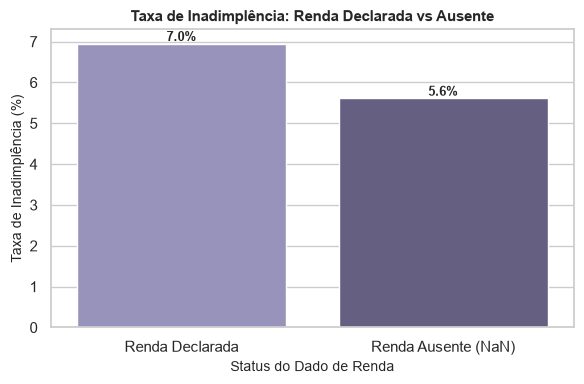

In [8]:
# Criando cópia temporária
df_h3 = df_limpo.copy()

# Criando a flag de renda ausente para teste
df_h3['income_missing'] = df_h3['MonthlyIncome'].isna()

# Calculando a taxa de inadimplência cruzando quem tem renda vs quem não tem 
analise_h3 = df_h3.groupby('income_missing', observed=False)['SeriousDlqin2yrs'].agg(
    total_clientes='count',
    inadimplentes='sum',
    taxa_inadimplencia='mean'
).reset_index()

analise_h3['status_renda'] = analise_h3['income_missing'].map({False: 'Renda Declarada', True: 'Renda Ausente (NaN)'})
analise_h3['taxa_inadimplencia (%)'] = (analise_h3['taxa_inadimplencia'] * 100).round(2)

print("Taxa de Inadimplência por Presença de Renda Declarada:")
display(analise_h3[['status_renda', 'total_clientes', 'inadimplentes', 'taxa_inadimplencia (%)']])

# Visualização gráfica
plt.figure(figsize=(6, 4))
ax = sns.barplot(
    x='status_renda',
    y='taxa_inadimplencia (%)',
    data=analise_h3,
    palette='Purples_d',
    hue='status_renda',
    legend=False
)
plt.title('Taxa de Inadimplência: Renda Declarada vs Ausente', fontsize=11, fontweight='bold')
plt.xlabel('Status do Dado de Renda', fontsize=10)
plt.ylabel('Taxa de Inadimplência (%)', fontsize=10)

for p in ax.patches:
    height = p.get_height() # type: ignore
    if pd.notnull(height) and height >0:
        ax.annotate(f'{height:.1f}%',
                    (p.get_x() + p.get_width() / 2., height), # type: ignore
                    ha='center', va='bottom',
                    fontsize=9, fontweight='bold')

plt.tight_layout()

# Salvando a imagem
output_dir = os.path.join("..", "output")
os.makedirs(output_dir, exist_ok=True)
caminho_imagem = os.path.join(output_dir, "taxa_inadim_renda_declarada_vs_ausente.png")
plt.savefig(caminho_imagem, dpi=300, bbox_inches='tight')

plt.show()

**Hipótese 3: Parcialmente Refutada (mas com ganho preditivo confirmado)**

- Quebra de Premissa do Risco Bruto: A hipótese original previa que clientes sem renda declarada concentrariam o maior risco de inadimplência. O gráfico e os dados provam o oposto: o grupo com Renda Declarada possui uma taxa de inadimplência ligeiramente maior (6,95%) do que o grupo com Renda Ausente (5,61%).

- Confirmação da Necessidade da Flag (O Valor Oculto): Embora a ausência de renda não signifique maior inadimplência isolada, o perfil de risco é diferente e não aleatório (5,61% vs 6,95%). Isso valida a nossa decisão estratégica de não descartar os dados e criar a flag binária de ausência, permitindo que o modelo aprenda esse comportamento específico sem distorcer o valor imputado da renda.

## Imputação Final de Dados e Persistência da Base Tratada

Com a EDA e a validação de hipóteses concluídas, vamos executar o tratamento dos valores nulos restantes:

* `MonthlyIncome`: Imputação da mediana na coluna e criação da flag binária `Renda_Ausente_Flag` para preservar o sinal comportamental da ausência.

* `NumberOfDependents`: Imputação simples pela mediana.

* Colunas de Atraso: Os `NaN` gerados pela neutralização dos códigos `96`/`98` serão mantidos como nulos, aproveitando a capacidade nativa dos algoritmos de *Gradient Boosting* (como XGBoost) de lidar com valores ausentes e isolar esse comportamento de alto risco.

Por fim, salvaremos a base limpa no banco SQLite para consumo no notebook de engenharia de recursos.

In [9]:
## Executando Imputações Finais e Salvando a Base

df_final = df_limpo.copy()

# Criando a Flag de Renda Ausente antes de imputar
df_final['Renda_Ausente_Flag'] = df_final['MonthlyIncome'].isna().astype(int)

# Imputando MonthlyIncome pela mediana da própria base
mediana_renda = df_final['MonthlyIncome'].median()
df_final['MonthlyIncome'] = df_final['MonthlyIncome'].fillna(mediana_renda)
print(f"MonthlyIncome imputado pela mediana: {mediana_renda}")

# Imputando NumberOfDependents pela mediana
mediana_dependentes = df_final['NumberOfDependents'].median()
df_final['NumberOfDependents'] = df_final['NumberOfDependents'].fillna(mediana_dependentes)
print(f"NumberOfDependents imputado pela mediana: {mediana_dependentes}")

# Verificando se ainda restam nulos no DataFrame principal (exceto as colunas de atraso que optamos por manter NaN)
print("\nVerificação de Nulos Restantes:")
display(df_final.isnull().sum())

# Salvando a base tratada de volta no banco SQLite (tabela 'credito_tratado')
conexao = sqlite3.connect("../data/credit_scoring.db")
df_final.to_sql("credito_tratado", conexao, if_exists="replace", index=False)
conexao.close()

print(f"\nBase tratada salva com sucesso na tabela 'credito_tratado'! Dimensões finais: {df_final.shape}")

MonthlyIncome imputado pela mediana: 5400.0
NumberOfDependents imputado pela mediana: 0.0

Verificação de Nulos Restantes:


SeriousDlqin2yrs                          0
RevolvingUtilizationOfUnsecuredLines      0
age                                       0
NumberOfTime30-59DaysPastDueNotWorse    269
DebtRatio                                 0
MonthlyIncome                             0
NumberOfOpenCreditLinesAndLoans           0
NumberOfTimes90DaysLate                 269
NumberRealEstateLoansOrLines              0
NumberOfTime60-89DaysPastDueNotWorse    269
NumberOfDependents                        0
Renda_Ausente_Flag                        0
dtype: int64


Base tratada salva com sucesso na tabela 'credito_tratado'! Dimensões finais: (149999, 12)


## Conclusão da EDA 

A exploração e o tratamento da base *Give Me Some Credit* permitiram validar as premissas de negócio e blindar o pipeline contra anomalias técnicas. Abaixo, um resumo dos principais achados e as diretrizes estratégicas para o próximo notebook (`03_feature_engineering.ipynb`):

#### Resumo dos Achados (Validação de Hipóteses)

* Utilização de Crédito (Hipótese 1): Confirmada com forte poder discriminatório. O risco de inadimplência explode de 2,2% (uso até 30%) para impressionantes 40,1% na faixa de 100% a 200% de utilização.

* Histórico de Atrasos (Hipótese 2): Confirmada com progressão estritamente monotônica. Acumular atrasos de 30 a 59 dias eleva o risco de forma exponencial, destacando-se o subgrupo de "Erros/Ausentes" (códigos 96/98), que revelou uma taxa de default crítica de 54,6%.

* Ausência de Renda (Hipótese 3): Parcialmente refutada no risco bruto (clientes sem renda declarada possuem default ligeiramente menor: 5,6% vs 7,0%), mas validada quanto à necessidade de controle: a criação da flag `Renda_Ausente_Flag` isola com sucesso esse comportamento diferenciado para os modelos preditivos.